## VIDEO 1.3 - Solving our Problem using K-means Part 1

**Problem Statement**: Try out new-age bundled online marketing strategies which would require to group similiar products together irrespective of the segment.

### The 6-step plan outlined:
1. Load the dataset
2. Feature selection
3. Preprocess the data
4. Apply K-Means
5. Find the optimal number of clusters (k)
6. Evaluate and interpret the clusters

### Import the necessary libraries 


### Step 1: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import os

os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module6')
data_preprocessed = pd.read_csv('Synergix_data_preprocessed_unsupervised_new.csv')
data_preprocessed.head()

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,SKU1011,2021-01-02,4119.0,4650,6.671449,697,Makeup,29.0,21.0,49.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,SKU1011,2021-01-09,4074.0,11435,11.134372,1027,Makeup,36.0,28.0,62.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,SKU1011,2021-01-16,4897.0,11603,11.189007,1037,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,SKU1011,2021-01-23,4783.0,14067,11.880912,1184,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SKU1011,2021-01-30,3789.0,6188,7.063927,876,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Step 2: Processing and feature selection for clustering

In [4]:
# Sorting by SKU_ID and Date

data_preprocessed.sort_values(by=['SKU_ID', 'Date'], inplace=True)
data_preprocessed

,SKU_ID,Date,Page_traffic,Revenue($),Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,...,Num_of_Promotions,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline
0,SKU1011,2021-01-02,4119.0,4650,6.671449,697,Makeup,29.0,21.0,49.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,SKU1011,2021-01-09,4074.0,11435,11.134372,1027,Makeup,36.0,28.0,62.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,SKU1011,2021-01-16,4897.0,11603,11.189007,1037,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,SKU1011,2021-01-23,4783.0,14067,11.880912,1184,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,SKU1011,2021-01-30,3789.0,6188,7.063927,876,Makeup,38.0,30.0,64.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19626,SKU998,2022-12-03,3206.0,32011,17.247306,1856,Makeup,79.0,56.0,149.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19627,SKU998,2022-12-10,1670.0,29417,17.083043,1722,Makeup,79.0,56.0,149.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19628,SKU998,2022-12-17,1554.0,19292,13.919192,1386,Makeup,79.0,56.0,149.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
19629,SKU998,2022-12-24,1117.0,22950,17.887763,1283,Makeup,79.0,56.0,149.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Checking All Column Names

A quick inventory of all 28 columns before you decide which ones to keep. This is good practice before feature selection — you want to know what you're working with.

In [3]:
data_preprocessed.columns.tolist()

['SKU_ID',
 'Date',
 'Page_traffic',
 'Revenue($)',
 'Unit_price',
 'Units_sold',
 'Segment',
 '1_Star_Rating',
 '2_Star_Rating',
 '3_Star_Rating',
 '4_Star_Rating',
 '5_Star_Rating',
 'Image_Count',
 'Bullet_Count',
 'Title_Count',
 'Description_Length',
 'num_unique_Search_Terms',
 'Organic Search Rank',
 'Num_of_Promotions',
 'Sum of Spend',
 'Online_Clicks',
 'Online_Cost',
 'Online_Impressions',
 'num_unique_campaigns',
 'Clicks_video',
 'Cost_video',
 'Impressions_video',
 'num_unique_campaigns_offline']

### Creating the Aggregated Dataset

**Why these 13 features specifically?** They capture the key dimensions for marketing bundling:
- **Visibility**: Page_traffic, Organic Search Rank
- **Listing quality**: Image_Count, Bullet_Count, Title_Count, Description_Length
- **Customer perception**: all 5 rating columns
- **Commercial performance**: Unit_price, Revenue($)

In [5]:
# Define the aggregation operations
aggregation = {
    
    'Page_traffic':'last',
    'Organic Search Rank': 'last',
    'Image_Count': 'last',
    'Bullet_Count': 'last',
    'Title_Count': 'last',
    'Description_Length': 'last',
     '1_Star_Rating': 'last',
     '2_Star_Rating': 'last',
     '3_Star_Rating': 'last',
     '4_Star_Rating': 'last',
     '5_Star_Rating': 'last',  
    'Unit_price':'last',
    'Revenue($)': 'sum',
}

**Why '*last*' for most columns?** 
- Features like *Image_Count*, *Unit_price*, *Page_traffic*, and ratings accumulate over time. 
- The most recent week's value is the best current snapshot of the product. You want to know what the product looks like *now*, not its average across all weeks.

**Why '*sum*' for Revenue($)?** 
- Revenue is additive — you want the product's *total earnings* over the entire period, not just the last week's revenue. 
- A product with consistently moderate weekly revenue for a full year should show higher total revenue than one with one great week.

In [6]:
# Group by 'SKU_ID' and aggregate
# data_selected = data_preprocessed.groupby('SKU_ID').agg(aggregation).reset_index()
"""
Whats' Happening:
- Collapsing the entire time series — all weekly rows per product — into one single row per product.
- After the below, each SKU_ID appears exactly once.
"""
data_selected = data_preprocessed.groupby('SKU_ID').agg(aggregation)
data_selected

,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($)
SKU_ID,,,,,,,,,,,,,
SKU1011,4995.0,14.0,5.0,5.0,91.0,59.0,75.0,50.0,118.0,237.0,1672.0,18.095471,1805434
SKU1014,87.0,32.0,0.0,5.0,79.0,99.0,89.0,49.0,146.0,257.0,1651.0,20.099526,0
SKU1024,5454.0,30.0,0.0,8.0,163.0,158.0,106.0,66.0,205.0,440.0,2996.0,15.980161,2340227
SKU1025,5356.0,27.0,2.0,6.0,90.0,62.0,152.0,102.0,287.0,604.0,4098.0,19.634593,2432316
SKU1036,3627.0,24.0,12.0,8.0,126.0,221.0,140.0,78.0,228.0,474.0,3479.0,25.186318,2839170
...,...,...,...,...,...,...,...,...,...,...,...,...,...
SKU968,875.0,19.0,9.0,5.0,85.0,56.0,57.0,39.0,116.0,273.0,1803.0,20.905660,0
SKU978,6056.0,30.0,0.0,8.0,167.0,158.0,14.0,9.0,0.0,74.0,533.0,18.176868,2211515
SKU989,583.0,28.0,13.0,6.0,62.0,122.0,162.0,107.0,277.0,571.0,3809.0,20.905660,0


### Checking for Missing Values
- Standard check before scaling. 
- Missing values will break StandardScaler — you need to know if any exist and handle them before proceeding.

In [7]:
# Identify missing values in data_selected
data_selected.isnull().sum()

Page_traffic           0
Organic Search Rank    0
Image_Count            0
Bullet_Count           0
Title_Count            0
Description_Length     0
1_Star_Rating          0
2_Star_Rating          0
3_Star_Rating          0
4_Star_Rating          0
5_Star_Rating          0
Unit_price             0
Revenue($)             0
dtype: int64

### Step 3: Scaling the Data to normalize the features

**Critical for K-Means — more so than for decision trees.**

In [8]:
from sklearn.preprocessing import StandardScaler

# Standardize the numerical columns
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_selected) # — learns the mean and std of each column, then transforms. Returns a numpy array.

# Create a DataFrame for the scaled data — wraps it back into a DataFrame, preserving column names and SKU_ID as the index so you can still identify which product is which.
data_scaled = pd.DataFrame(data_scaled, columns=data_selected.columns, index = data_selected.index)

# Show the first few rows of the scaled DataFrame
data_scaled.head()


,Page_traffic,Organic Search Rank,Image_Count,Bullet_Count,Title_Count,Description_Length,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Unit_price,Revenue($)
SKU_ID,,,,,,,,,,,,,
SKU1011,1.100784,-0.411851,-0.411446,-1.576290,-0.551930,-1.284448,-0.209573,-0.229204,-0.389066,-0.409205,-0.320630,-0.627850,-0.062109
SKU1014,-1.351049,1.041026,-1.427309,-1.576290,-0.962336,-0.632472,0.013749,-0.252124,-0.162427,-0.330060,-0.333027,-0.398543,-1.624228
SKU1024,1.330081,0.879595,-1.427309,1.486582,1.910506,0.329194,0.284926,0.137522,0.315134,0.394121,0.460978,-0.869888,0.400611
SKU1025,1.281125,0.637449,-1.020964,-0.555332,-0.586131,-1.235550,1.018701,0.962656,0.978863,1.043114,1.111530,-0.451741,0.480290
SKU1036,0.417388,0.395303,1.010763,1.486582,0.645087,1.356056,0.827281,0.412567,0.501302,0.528668,0.746111,0.183498,0.832313


Flow so far:
```python
Raw time-series data (19,631 rows)
    ↓ sort by SKU + Date
    ↓ aggregate to one row per product
    ↓ select 13 meaningful features
    ↓ check for nulls
    ↓ scale to equal footing
Product-level matrix, ready for K-Means
```

## VIDEO 1.4 - Solving our Problem using K-means Part 2

### Step 4: Apply K-Means Clustering

**Fitting K-Means with Default Settings**

- *KMeans(random_state=42)* — creates the model with **default n_clusters=8**. You haven't specified how many clusters you want yet — you're letting sklearn use its default to see what comes out. This is exploratory.

- *kmeans.fit(data_scaled)* — runs the algorithm on your scaled product matrix. It finds the 8 centroids that best partition the products.
- *kmeans.predict(data_scaled)* — assigns a cluster label (0 through 7) to every product.  

**Note**: unlike supervised learning, you're predicting on the same data you trained on — there's no separate test set in clustering. The goal is to understand the structure of the data, not generalize to new data.
- *data_visual = data_scaled.copy()* — creates a copy of the scaled data to add the cluster labels to. You use a copy to avoid modifying data_scaled itself.
- *data_visual['Cluster_Labels'] = cluster_labels* — attaches the cluster assignment as a new column
- *.value_counts()* — shows how many products landed in each cluster, so you can see if the clusters are roughly balanced or heavily skewed

In [16]:
from sklearn.cluster import KMeans

# Fit KMeans with its default number of clusters
kmeans = KMeans(random_state=42)
kmeans.fit(data_scaled)
cluster_labels = kmeans.predict(data_scaled)
data_visual = data_scaled.copy()
data_visual['Cluster_Labels'] = cluster_labels
data_visual['Cluster_Labels'].value_counts()

Cluster_Labels
0    45
6    35
1    34
3    30
5    29
7    23
4    23
2    20
Name: count, dtype: int64

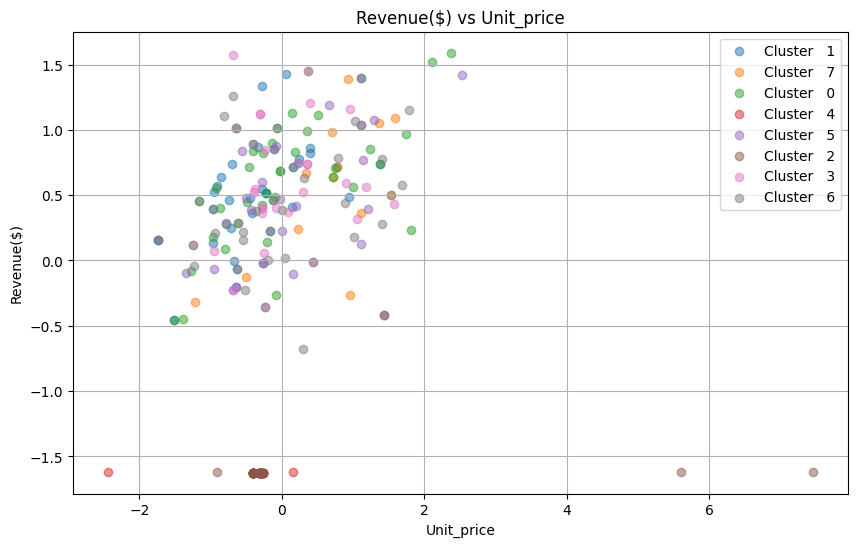

In [13]:
import matplotlib.pyplot as plt
# Create a scatter plot with different colors for each cluster
plt.figure(figsize=(10, 6))

#Cluster_label is the variable that will take on the value of each unique cluster label as the for loop iterates.
for cluster_label in data_visual['Cluster_Labels'].unique():  
#This DataFrame is a subset of data_visual where 'Cluster_Labels' is equal to the current value of cluster_label being processed in the loop.
    cluster_data = data_visual[data_visual['Cluster_Labels'] == cluster_label]
#This line plots a scatter plot using matplotlib.pyplot (abbreviated as plt)    
    plt.scatter(cluster_data['Unit_price'], cluster_data['Revenue($)'], label=f'Cluster   {cluster_label}', alpha=0.5)

plt.xlabel('Unit_price')
plt.ylabel('Revenue($)')
plt.title('Revenue($) vs Unit_price')
plt.legend()
plt.grid(True)
plt.show()  


**What to look for in the output**: 
- Do the colored groups visually separate? If the clusters are meaningful, you should see groups of dots that hang together in distinct regions of the plot. 
- If everything is a jumbled mess of mixed colors, the current k=8 **may not** be the right choice.

#### Re-fitting with 5 Clusters

**Manually trying different k clusters**

In [14]:
# Fit KMeans with  clusters
kmeans = KMeans(n_clusters=5, random_state=42)  
kmeans.fit(data_scaled)
cluster_labels = kmeans.predict(data_scaled)

data_visual['Cluster_Labels'] = cluster_labels

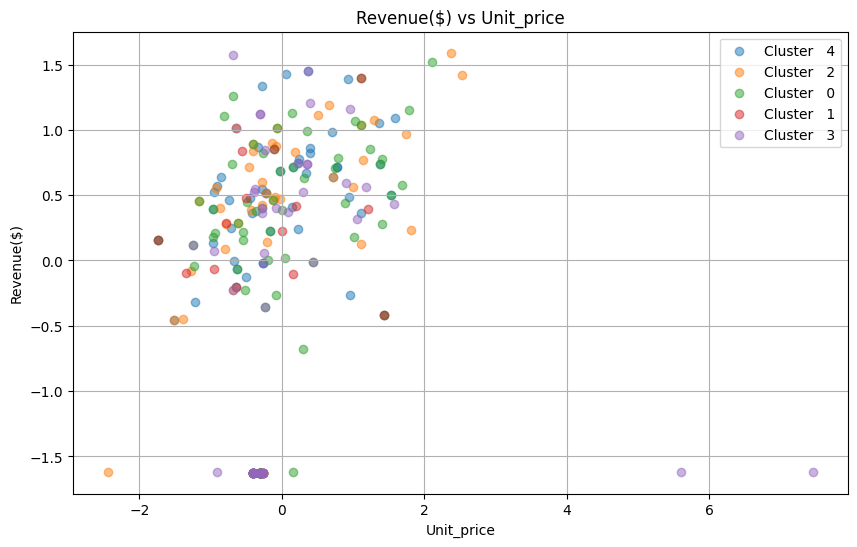

In [15]:
# Create a scatter plot with different colors for each cluster
plt.figure(figsize=(10, 6))

for cluster_label in data_visual['Cluster_Labels'].unique():  
    cluster_data = data_visual[data_visual['Cluster_Labels'] == cluster_label]
    plt.scatter(cluster_data['Unit_price'], cluster_data['Revenue($)'], label=f'Cluster   {cluster_label}', alpha=0.5)


plt.xlabel('Unit_price')
plt.ylabel('Revenue($)')
plt.title('Revenue($) vs Unit_price')
plt.legend()
plt.grid(True)
plt.show()  # Add this line to display the plot


Observation:
- Still a mess
- Doesnt look any clean compare to k = 8

## Video 1.5 - Finding the Optimal number of Clusters (K)

### Step 5: Plot the elbow plot to find optimal K value

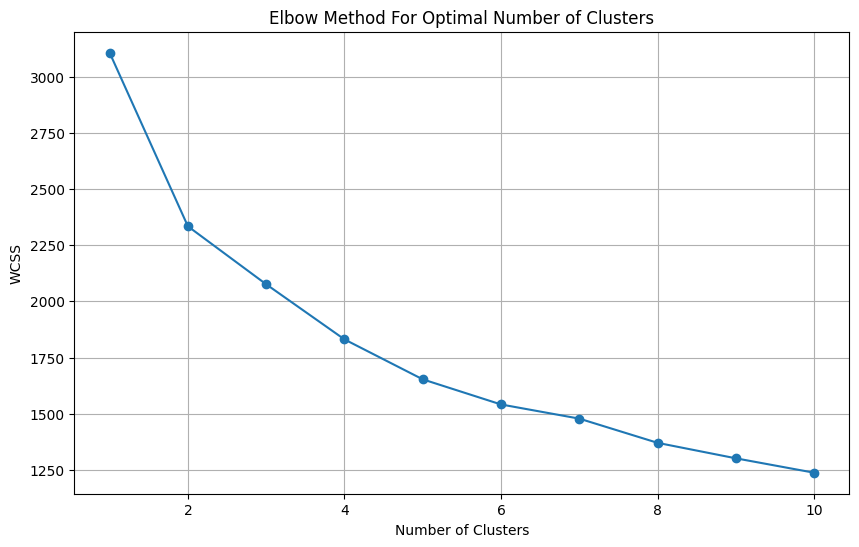

In [17]:
# Define a range of cluster counts to test
cluster_range = range(1, 11)  # You can adjust the upper limit as needed

# Initialize an empty list to store the WCSS values for different number of clusters
wcss = []

# KMeans for each cluster count and store WCSS
for i in cluster_range:
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(data_scaled)
    wcss.append(kmeans.inertia_)
    

# Plot the Elbow method
plt.figure(figsize=(10, 6))
plt.plot(cluster_range, wcss, marker='o')
plt.title('Elbow Method For Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()


Observation:
- **no sharp, obvious** elbow. 
- The curve bends gradually rather than kinking cleanly. 
- A reasonable person could look at this plot and argue for k=2, k=3, k=4, or even k=5 — and they wouldn't be wrong to question it.

In [18]:
from sklearn.metrics import silhouette_score

# Define a range of cluster counts to test
cluster_range = range(2, 10)  # Start from 2 clusters - Silhouette score requires at least 2 clusters — with k=1 there's nothing to compare separation against.

# Initialize variables for silhouette scores
silhouette_scores = []

# Silhouette score for each cluster count
for i in cluster_range:
    kmeans = KMeans(n_clusters=i, n_init=10, random_state=42)
    kmeans.fit(data_scaled)
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(data_scaled, labels)
    silhouette_scores.append(silhouette_avg)

# Print Silhouette scores
for i, score in zip(cluster_range, silhouette_scores):
    print(f'Number of Clusters: {i}, Silhouette Score: {score}')


Number of Clusters: 2, Silhouette Score: 0.20753738750227463
Number of Clusters: 3, Silhouette Score: 0.19130013700985213
Number of Clusters: 4, Silhouette Score: 0.17664286048540764
Number of Clusters: 5, Silhouette Score: 0.17321943891084296
Number of Clusters: 6, Silhouette Score: 0.1631588862676473
Number of Clusters: 7, Silhouette Score: 0.17809295380720766
Number of Clusters: 8, Silhouette Score: 0.17332486717055587
Number of Clusters: 9, Silhouette Score: 0.18461982131263305


Observation:
No. Clusters: 2 has the highest Silhouette Score thus our **optimal k value is 2**.

### Cluster the data using K-means algorithm

In [ ]:

optimal_k = 2 # <- Fill in the optimal k

# Fit KMeans with optimal k clusters
kmeans = KMeans(n_clusters= optimal_k, random_state=42)  
kmeans.fit(data_scaled)
cluster_labels = kmeans.predict(data_scaled)

data_visual['Cluster_Labels'] = cluster_labels

## Video 1.6 - Analysis and Insights Based on the Plots

### Step 6: Evaluate and Interpret the Clusters

#### Plot 1: Unit_price vs Revenue

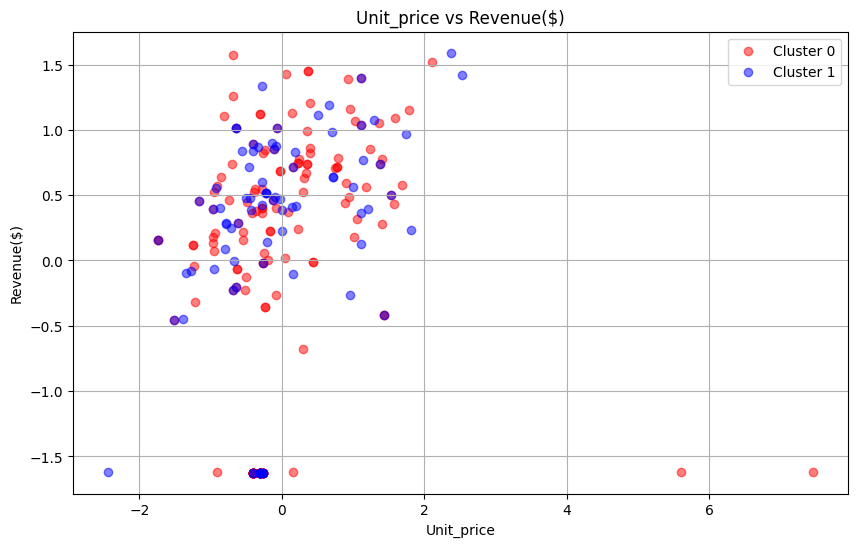

In [28]:
# Create a list of colors for each cluster
colors = ['red', 'blue']

# Create a scatter plot with different colors for each cluster
plt.figure(figsize=(10, 6)) #(10, 6)

for cluster_label, color in enumerate(colors):
    cluster_data = data_visual[data_visual['Cluster_Labels'] == cluster_label]
    plt.scatter(cluster_data['Unit_price'], cluster_data['Revenue($)'], label=f'Cluster {cluster_label}', color=color, alpha=0.5)

plt.xlabel('Unit_price')
plt.ylabel('Revenue($)')
plt.title('Unit_price vs Revenue($)')
plt.legend()
plt.grid(True)
plt.show()


Observation:
- The bulk of both clusters heavily overlap in the central zone (Unit_price: -1 to 1, Revenue: -0.5 to 1.5)
- There is a distinct bottom band at Revenue ≈ -1.65 — almost entirely red (Cluster 0)
- A few red dots extend far right to Unit_price of 4–6 — very expensive products
- Blue dots are absent from both the **bottom band** and the extreme right

**Interpretation**: 
- Unit_price alone doesn't separate the clusters. 
- But the bottom-revenue band being almost entirely Cluster 0 is your first real signal — **Cluster 0 contains the lowest-revenue products in the dataset**.

#### Plot 2: Title_Count vs Revenue($)


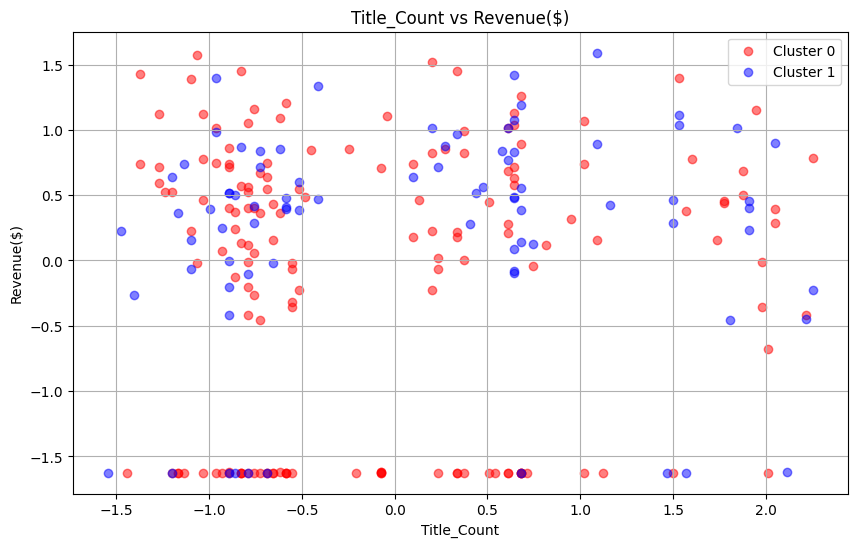

In [29]:
# Create a list of colors for each cluster
colors = ['red', 'blue']

# Create a scatter plot with different colors for each cluster
plt.figure(figsize=(10, 6))

for cluster_label, color in enumerate(colors):
    cluster_data = data_visual[data_visual['Cluster_Labels'] == cluster_label]
    plt.scatter(cluster_data['Title_Count'], cluster_data['Revenue($)'], label=f'Cluster {cluster_label}', color=color, alpha=0.5)

plt.xlabel('Title_Count')
plt.ylabel('Revenue($)')
plt.title('Title_Count vs Revenue($)')
plt.legend()
plt.grid(True)
plt.show()


Observation:
- Same heavy overlap in the central region — both clusters mix freely across all Title_Count values

- The **bottom revenue band** (≈ -1.65) is again almost entirely red (Cluster 0)

- Blue dots are slightly more concentrated around Title_Count 0–1 (middle range)
- No clean horizontal or vertical separation

**Interpretation**: 
- Title quality doesn't clearly distinguish the clusters on its own. 
- But the pattern from Plot 1 is confirmed — **Cluster 0 consistently occupies the bottom revenue zone** across multiple axes.

#### Plot 3: Page_traffic vs Revenue($)

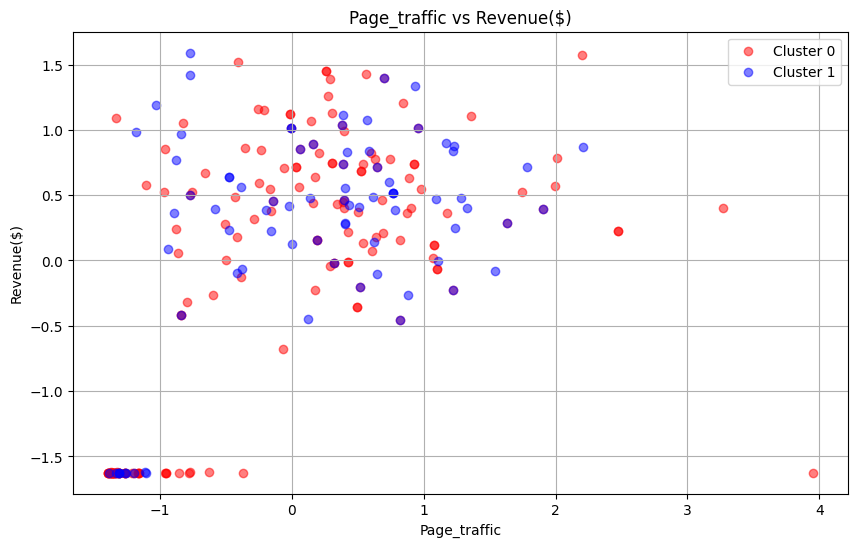

In [30]:
# Create a list of colors for each cluster
colors = ['red', 'blue']

# Create a scatter plot with different colors for each cluster
plt.figure(figsize=(10, 6))

for cluster_label, color in enumerate(colors):
    cluster_data = data_visual[data_visual['Cluster_Labels'] == cluster_label]
    plt.scatter(cluster_data['Page_traffic'], cluster_data['Revenue($)'], label=f'Cluster {cluster_label}', color=color, alpha=0.5)

plt.xlabel('Page_traffic')
plt.ylabel('Revenue($)')
plt.title('Page_traffic vs Revenue($)')
plt.legend()
plt.grid(True)
plt.show()


Observation:
- Bottom-left corner (low traffic ≈ -1, low revenue ≈ -1.65) is **almost entirely red** (Cluster 0) — this is the most structured signal of all three plots
- Blue dots are largely absent from the bottom-left — they cluster more in the middle traffic range (0 to 1)
- One red dot extends to very high Page_traffic (≈ 4) but still has only moderate revenue — high traffic but poor conversion

**Interpretation**: 
- This is the most revealing plot. 
- **Low page traffic AND low revenue = Cluster 0**. The combination of both features being low is a strong Cluster 0 signal.